In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [4]:
# Create dataset
np.random.seed(42)

normal_data = np.random.normal(
    loc=50,
    scale=5,
    size=(1000, 1)
)

print("Dataset Shape:", normal_data.shape)
print("First 10 Values:")
print(normal_data[:10])

Dataset Shape: (1000, 1)
First 10 Values:
[[52.48357077]
 [49.30867849]
 [53.23844269]
 [57.61514928]
 [48.82923313]
 [48.82931522]
 [57.89606408]
 [53.83717365]
 [47.65262807]
 [52.71280022]]


In [5]:
# Normalize dataset
normal_data = normal_data / 100.0

In [6]:
# split dataset 
x_train = normal_data[:800]
x_test = normal_data[800:]

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (800, 1)
Testing Data: (200, 1)


In [7]:
# Encoder 
encoder = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(1,)),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu')
])

C:\Users\Asus\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# decoder
decoder = keras.Sequential([
    layers.Dense(8, activation='relu', input_shape=(4,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [9]:
# Combine encoder and decoder 
autoencoder = keras.Sequential([
    encoder,
    decoder
])
autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 4)                   │             204 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, 1)                   │             201 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 405 (1.58 KB)

 Trainable params: 405 (1.58 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [12]:
# Train autoencoder 
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0024 - mae: 0.0389 - val_loss: 0.0023 - val_mae: 0.0381
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0024 - mae: 0.0386 - val_loss: 0.0022 - val_mae: 0.0376
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0023 - mae: 0.0383 - val_loss: 0.0022 - val_mae: 0.0369
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0022 - mae: 0.0376 - val_loss: 0.0021 - val_mae: 0.0363
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0021 - mae: 0.0364 - val_loss: 0.0019 - val_mae: 0.0346
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0019 - mae: 0.0346 - val_loss: 0.0016 - val_mae: 0.0322
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016 - mae: 0.0316 - val_loss: 0.0013 - val_mae: 0.0298
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0012 - mae: 0.0275 - val_loss: 8.3949e-04 - val_mae: 0.0232
Epoch 9/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.3507e-04

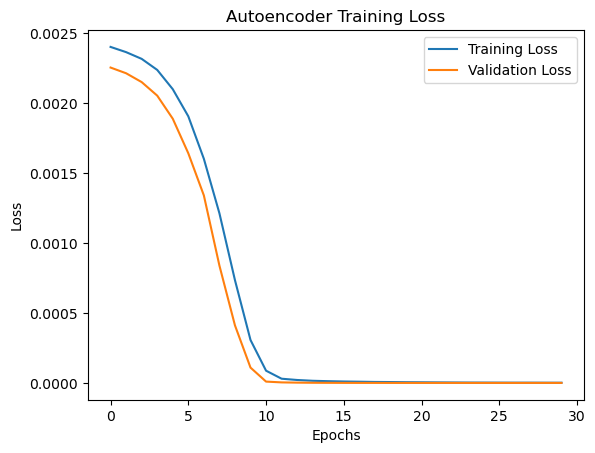

In [13]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [15]:
anomalies = np.array([
    [1.2],
    [1.5],
    [1.8],
    [2.0]
])

In [16]:
test_data = np.concatenate([
    x_test,
    anomalies
])

In [17]:
reconstructed = autoencoder.predict(test_data)

reconstruction_error = np.mean(
    np.square(test_data - reconstructed),
    axis=1
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [18]:
threshold = np.percentile(
    np.mean(np.square(
        x_train - autoencoder.predict(x_train)
    ), axis=1),
    95
)

print("Anomaly Threshold:", threshold)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Anomaly Threshold: 1.688822654409022e-07


In [19]:
predictions = reconstruction_error > threshold

for i in range(len(test_data)):
    if predictions[i]:
        print(test_data[i][0] * 100, "Anomaly")
    else:
        print(test_data[i][0] * 100, "Normal")

54.69141902987998 Normal
47.41977635891313 Normal
50.48060388470492 Normal
47.68862355647479 Normal
47.827518862838424 Normal
48.454139382656805 Normal
51.11066885816856 Normal
47.60625689168261 Normal
56.27878062786761 Normal
45.52696348890248 Normal
49.06564177919321 Normal
47.801344708629124 Normal
57.23488942176866 Normal
50.98277388255787 Normal
55.15922269734318 Anomaly
42.57219813481514 Normal
51.335251329346285 Normal
54.44815397811718 Normal
50.41141994637712 Normal
55.32740187532676 Normal
47.41355774949814 Normal
57.0467372009279 Normal
61.49449061809625 Anomaly
48.18580719780171 Normal
47.77248739299614 Normal
57.2669223855885 Normal
57.89786072865356 Normal
47.38569986423366 Normal
47.89906591452071 Normal
48.59107695569747 Normal
43.27774744482861 Normal
45.40674026757901 Normal
44.97929616623966 Normal
46.16101217447936 Normal
49.82657556306609 Normal
51.171073662682595 Normal
57.752502464070375 Normal
45.00822979630605 Normal
54.92161199238292 Anomaly
48.93005577887246 

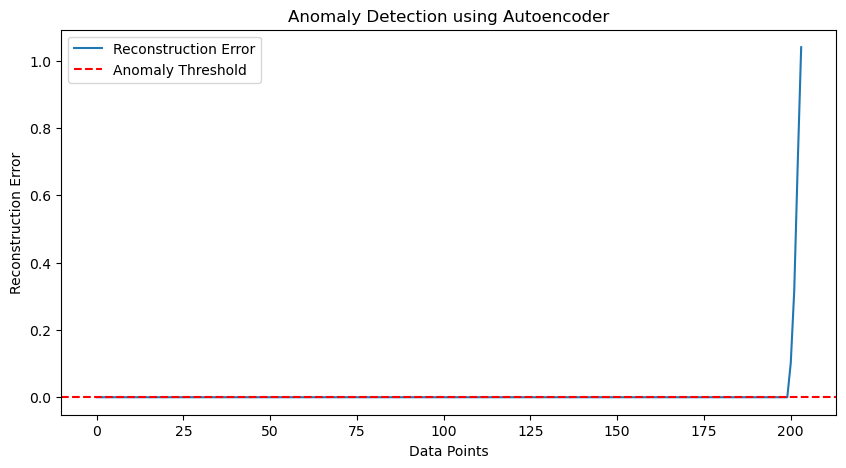

In [20]:
plt.figure(figsize=(10,5))

plt.plot(reconstruction_error, label='Reconstruction Error')

plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("Anomaly Detection using Autoencoder")
plt.xlabel("Data Points")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()